In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

easy_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/easy lokesh labelling.xlsx')
normal_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook1.xlsx')
medium_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook2.xlsx')
hard_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook3.xlsx')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
dfs = [easy_df, normal_df, medium_df, hard_df]
for d in dfs:
    d.columns = d.columns.str.strip().str.lower()

easy_df.rename(columns={'peak x': 'peek x', 'peak y': 'peek y'}, inplace=True)

core_features = ['start x', 'start y', 'end x', 'end y', 'peek x', 'peek y', 'n1', 'n2', 'noise x', 'noise y']
easy_df = easy_df[core_features].copy()

easy_df['activity type'] = 'easy'
easy_df['person_id'] = 2.0

for d in [normal_df, medium_df, hard_df]:
    d.columns = d.columns.str.strip().str.lower()

data = pd.concat([easy_df, normal_df, medium_df, hard_df], ignore_index=True)
data = data.loc[:, ~data.columns.str.contains('unnamed')]

data['activity type'] = data['activity type'].astype(str).str.strip().str.lower()

valid_classes = ['normal', 'easy', 'medium', 'hard']
data = data[data['activity type'].isin(valid_classes)].copy()

print("Dataset shape:", data.shape)
print("\nClass distribution:")
print(data['activity type'].value_counts())
data.head(280)

Dataset shape: (307, 12)

Class distribution:
activity type
easy      80
normal    77
hard      76
medium    74
Name: count, dtype: int64


,start x,start y,end x,end y,peek x,peek y,n1,n2,noise x,noise y,activity type,person_id
0,4.5688,0.000024,8.6235,0.000150,6.524660,0.003083,5.0,4.0,8.6403,0.000193,easy,2.0
1,13.1205,0.000103,7.2639,0.000119,15.731823,0.002184,4.0,2.0,17.3102,0.000513,easy,2.0
2,20.2443,0.000112,24.8933,0.000172,22.791160,0.002001,3.0,3.0,24.9150,0.000224,easy,2.0
3,30.8151,0.000170,36.0206,0.000123,33.856640,0.001535,4.0,3.0,36.1273,0.000175,easy,2.0
4,37.6092,0.000130,43.8875,0.000149,39.354610,0.001794,2.0,5.0,43.9777,0.000120,easy,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
278,376.3902,0.000141,383.2061,0.000137,380.309200,0.001228,5.0,3.0,383.2061,0.000137,hard,2.0
279,384.6015,0.000095,389.9001,0.000113,386.404100,0.001200,2.0,4.0,389.9001,0.000113,hard,2.0
280,392.6107,0.000127,400.1104,0.000031,397.700100,0.001424,6.0,3.0,400.1104,0.000031,hard,2.0
281,400.9017,0.000086,406.8091,0.000053,403.550100,0.001357,4.0,4.0,406.8091,0.000053,hard,2.0


In [5]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

X = data[core_features].values
y = data['activity type'].values

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

start_x, start_y = X_imputed[:, 0], X_imputed[:, 1]
end_x, end_y = X_imputed[:, 2], X_imputed[:, 3]
peek_x, peek_y = X_imputed[:, 4], X_imputed[:, 5]
n1, n2 = X_imputed[:, 6], X_imputed[:, 7]
noise_x, noise_y = X_imputed[:, 8], X_imputed[:, 9]

step_distance = np.sqrt((end_x - start_x)**2 + (end_y - start_y)**2)
peak_force = np.sqrt(peek_x**2 + peek_y**2)
noise_magnitude = np.sqrt(noise_x**2 + noise_y**2)
snr = peak_force / (noise_magnitude + 1e-5)
velocity_proxy = step_distance / (np.abs(end_x - start_x) + 1e-5)

X_enhanced = np.hstack([
    X_imputed,
    step_distance[:, None],
    peak_force[:, None],
    noise_magnitude[:, None],
    snr[:, None],
    velocity_proxy[:, None]
])

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_enhanced, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler_eng = StandardScaler()
X_train_eng_scaled = scaler_eng.fit_transform(X_train_eng)
X_test_eng_scaled = scaler_eng.transform(X_test_eng)

X_train_tensor = torch.tensor(X_train_eng_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_eng, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_eng_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_eng, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

print(f"Training Tensor Shape: {X_train_tensor.shape}")
print(f"Test Tensor Shape: {X_test_tensor.shape}")

Training Tensor Shape: torch.Size([245, 15])
Test Tensor Shape: torch.Size([62, 15])


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

class RegularizedFTTransformer(nn.Module):
    def __init__(self, num_features, num_classes, d_model=32, n_heads=2, num_layers=1):
        super().__init__()
        self.feature_embeddings = nn.Linear(1, d_model)
        self.feature_weights = nn.Parameter(torch.randn(num_features, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=64, dropout=0.3, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.layer_norm = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(num_features * d_model, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        batch_size, num_features = x.shape
        x_expanded = x.unsqueeze(-1)

        tokens = self.feature_embeddings(x_expanded) * self.feature_weights.unsqueeze(0)
        trans_out = self.transformer_encoder(tokens)
        trans_out = self.layer_norm(trans_out + tokens)

        flat = trans_out.reshape(batch_size, -1)
        return self.classifier(flat)

num_features = X_train_eng_scaled.shape[1]
num_classes = len(np.unique(y_train_eng))

ft_model = RegularizedFTTransformer(num_features=num_features, num_classes=num_classes)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(ft_model.parameters(), lr=0.001, weight_decay=0.05)

print("Regularized FT-Transformer initialized successfully!")

Regularized FT-Transformer initialized successfully!


Epoch [5/35] | Loss: 0.7256 | Train Acc: 79.59% | Test Acc: 62.90%
Epoch [10/35] | Loss: 0.6995 | Train Acc: 81.22% | Test Acc: 66.13%
Epoch [15/35] | Loss: 0.6827 | Train Acc: 79.18% | Test Acc: 69.35%
Epoch [20/35] | Loss: 0.6648 | Train Acc: 80.41% | Test Acc: 64.52%
Epoch [25/35] | Loss: 0.6469 | Train Acc: 85.31% | Test Acc: 64.52%
Epoch [30/35] | Loss: 0.6179 | Train Acc: 84.08% | Test Acc: 67.74%
Epoch [35/35] | Loss: 0.6248 | Train Acc: 84.90% | Test Acc: 70.97%


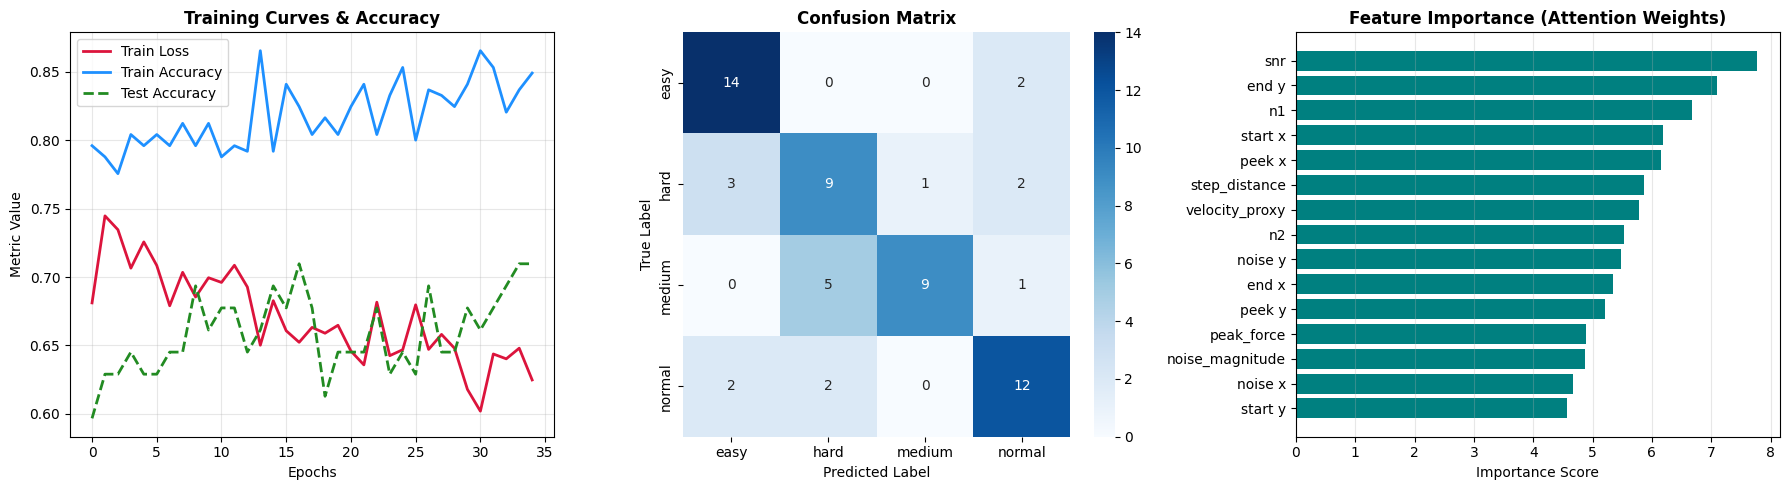


Final Test Accuracy: 70.97%

Classification Report:
              precision    recall  f1-score   support

        easy       0.74      0.88      0.80        16
        hard       0.56      0.60      0.58        15
      medium       0.90      0.60      0.72        15
      normal       0.71      0.75      0.73        16

    accuracy                           0.71        62
   macro avg       0.73      0.71      0.71        62
weighted avg       0.73      0.71      0.71        62



In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

history = {'train_loss': [], 'train_acc': [], 'test_acc': []}

ft_model.train()
for epoch in range(35):
    epoch_loss = 0
    correct_train = 0
    total_train = 0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = ft_model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        correct_train += (preds == batch_y).sum().item()
        total_train += batch_y.size(0)

    avg_loss = epoch_loss / len(train_loader)
    train_acc = correct_train / total_train

    ft_model.eval()
    with torch.no_grad():
        test_outs = ft_model(X_test_tensor)
        test_preds = torch.argmax(test_outs, dim=1)
        test_acc = (test_preds == y_test_tensor).sum().item() / len(y_test_tensor)
    ft_model.train()

    history['train_loss'].append(avg_loss)
    history['train_acc'].append(train_acc)
    history['test_acc'].append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/35] | Loss: {avg_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")


ft_model.eval()
with torch.no_grad():
    final_test_outputs = ft_model(X_test_tensor)
    y_pred = torch.argmax(final_test_outputs, dim=1).numpy()
    y_true = y_test_tensor.numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history['train_loss'], label='Train Loss', color='crimson', linewidth=2)
axes[0].plot(history['train_acc'], label='Train Accuracy', color='dodgerblue', linewidth=2)
axes[0].plot(history['test_acc'], label='Test Accuracy', color='forestgreen', linewidth=2, linestyle='--')
axes[0].set_title('Training Curves & Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Metric Value')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cm = confusion_matrix(y_true, y_pred)
class_names = label_encoder.classes_
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

with torch.no_grad():
    feat_importance = torch.norm(ft_model.feature_weights, dim=1).cpu().numpy()

feature_names = [
    'start x', 'start y', 'end x', 'end y', 'peek x', 'peek y',
    'n1', 'n2', 'noise x', 'noise y', 'step_distance',
    'peak_force', 'noise_magnitude', 'snr', 'velocity_proxy'
]

sorted_idx = np.argsort(feat_importance)
axes[2].barh(np.array(feature_names)[sorted_idx], feat_importance[sorted_idx], color='teal')
axes[2].set_title('Feature Importance (Attention Weights)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Importance Score')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('ft_transformer_evaluation_report.png', dpi=300)
plt.show()

print(f"\nFinal Test Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [10]:
import torch
checkpoint = {
    'model_state_dict': ft_model.state_dict(),
    'num_features': num_features,
    'num_classes': num_classes,
    'd_model': 32,
    'n_heads': 2,
    'num_layers': 1
}

torch.save(checkpoint, 'ft_transformer_complete_checkpoint.pth')
print("Complete model, weights, and parameters saved successfully as 'ft_transformer_complete_checkpoint.pth'")

Complete model, weights, and parameters saved successfully as 'ft_transformer_complete_checkpoint.pth'


In [11]:
from google.colab import files
files.download('ft_transformer_complete_checkpoint.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files

# Download the evaluation report plot image
files.download('ft_transformer_evaluation_report.png')
print("Download initiated for 'ft_transformer_evaluation_report.png'")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated for 'ft_transformer_evaluation_report.png'
